### Проект: Промышленность

Чтобы оптимизировать производственные расходы, металлургический комбинат «Стальная птица» решил уменьшить потребление электроэнергии на этапе обработки стали. Для этого комбинату нужно контролировать температуру сплава

Целью проекта является обучения модеи для предсказания конечной температуры сплава в партии

Данная цель рапыляется на следующие задачи: загрузка данных, исследовательский нализ данных, подготовка данных к обучению, обучение моделей, тестирование моделей

Описание данных: Данные хранятся в Sqlite  — СУБД, в которой база данных представлена одним файлом. Она состоит из нескольких таблиц:

steel.data_arc — данные об электродах;
steel.data_bulk — данные об объёме сыпучих материалов;
steel.data_bulk_time — данные о времени подачи сыпучих материалов;
steel.data_gas — данные о продувке сплава газом;
steel.data_temp — данные об измерениях температуры;
steel.data_wire — данные об объёме проволочных материалов;
steel.data_wire_time — данные о времени подачи проволочных материалов.


Таблица steel.data_arc
key — номер партии;
BeginHeat — время начала нагрева;
EndHeat — время окончания нагрева;
ActivePower — значение активной мощности;
ReactivePower — значение реактивной мощности.

Таблица steel.data_bulk
key — номер партии;
Bulk1 … Bulk15 — объём подаваемого материала.

Таблица steel.data_bulk_time
key — номер партии;
Bulk1 … Bulk15 — время подачи материала.

Таблица steel.data_gas
key — номер партии;
gas — объём подаваемого газа.

Таблица steel.data_temp
key — номер партии;
MesaureTime — время замера;
Temperature — значение температуры.

Таблица steel.data_wire
key — номер партии;
Wire1 … Wire9 — объём подаваемых проволочных материалов.

Таблица steel.data_wire_time
key — номер партии;
Wire1 … Wire9 — время подачи проволочных материалов.

Во всех файлах столбец key содержит номер партии. В таблицах может быть несколько строк с одинаковым значением key: они соответствуют разным итерациям обработки.

Для начала загрузим данные

In [1]:
!pip install skorch -q

In [2]:
!pip install shap phik -q

In [3]:
import numpy as np 
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import torch.nn as nn
import torch
import shap

from sqlalchemy import create_engine
from phik import phik_matrix
from phik.report import plot_correlation_matrix
from sklearn.tree import DecisionTreeRegressor
from skorch import NeuralNetRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, make_scorer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from catboost import CatBoostRegressor
from sklearn.tree import DecisionTreeRegressor

In [4]:
class EDA:
    
    def __init__(self, df):
        self.df = df
        
    def intro(self):
        if self.df is None:
            print('Все плохо')
            return
        
        print('Первые пять строк и базовая инфа')
        display(self.df.head(5))
        display(self.df.describe())
        self.df.info()
        
    def feature_display(self, int_cols):
        if self.df is None:
            print('Все плохо')
            return
        
        if int_cols:
            print('Гистограммы непрерывных признаков')
            n_cols = 3
            n_rows = math.ceil(len(int_cols) / n_cols)
            
            fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))
            axes = axes.flatten() 
            
            for i, column in enumerate(int_cols):
                sns.histplot(self.df, x=column,
                             kde=True, kde_kws={'bw_method': 0.6}, edgecolor='white', ax=axes[i])
                axes[i].set_title(f'Распределение признака\n«{column}»')
                axes[i].set_xlabel(column)
                axes[i].set_ylabel('Количество')

            for j in range(i + 1, len(axes)):
                axes[j].set_visible(False)
            
            plt.tight_layout()
            plt.show()
        
    def phik_matrix(self,int_cols):
        if self.df is None:
            print('Все плохо')
            return
            
        phik_overview = self.df.phik_matrix(interval_cols = int_cols)
        plt.figure(figsize=(20, 12))
        sns.heatmap(phik_overview, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5, center=0)
        plt.title("Матрица корреляций")
        plt.show()

!wget https://code.s3.yandex.net/data-scientist/ds-plus-final.db
path_to_db = 'ds-plus-final.db'
engine = create_engine(f'sqlite:///{path_to_db}', echo=False)

In [5]:
path_to_db = '/kaggle/input/datasets/gennadybudaev/dataset-vipusk/ds-plus-final.db'
engine = create_engine(f'sqlite:///{path_to_db}', echo=False)

оставлю свой вариант ниже

path_to_db = '/kaggle/input/datasets/gennadybudaev/dataset-vipusk/ds-plus-final.db'
engine = create_engine(f'sqlite:///{path_to_db}', echo=False)

In [6]:
query_data_arc = '''
SELECT *
FROM data_arc'''
arc = pd.read_sql_query(query_data_arc, con = engine)

query_data_bulk = '''
SELECT *
FROM data_bulk'''
bulk = pd.read_sql_query(query_data_bulk, con = engine)

query_data_bulk_time = '''
SELECT *
FROM data_bulk_time'''
bulk_time = pd.read_sql_query(query_data_bulk_time, con = engine)

query_data_gas = '''
SELECT *
FROM data_gas'''
gas = pd.read_sql_query(query_data_gas, con = engine)

query_data_temp = '''
SELECT *
FROM data_temp'''
temp = pd.read_sql_query(query_data_temp, con = engine)

query_data_wire = '''
SELECT *
FROM data_wire'''
wire = pd.read_sql_query(query_data_wire, con = engine)

query_data_wire_time = '''
SELECT *
FROM data_wire_time'''
wire_time = pd.read_sql_query(query_data_wire_time, con = engine)

In [7]:
data_arc = EDA(arc)
df_arc = data_arc.df.copy()
data_arc.intro()

Первые пять строк и базовая инфа


,key,Начало нагрева дугой,Конец нагрева дугой,Активная мощность,Реактивная мощность
0,1,2019-05-03 11:02:14,2019-05-03 11:06:02,0.305130,0.211253
1,1,2019-05-03 11:07:28,2019-05-03 11:10:33,0.765658,0.477438
2,1,2019-05-03 11:11:44,2019-05-03 11:14:36,0.580313,0.430460
3,1,2019-05-03 11:18:14,2019-05-03 11:24:19,0.518496,0.379979
4,1,2019-05-03 11:26:09,2019-05-03 11:28:37,0.867133,0.643691


,key,Активная мощность,Реактивная мощность
count,14876.000000,14876.000000,14876.000000
mean,1615.220422,0.662752,0.438986
std,934.571502,0.258885,5.873485
min,1.000000,0.223120,-715.479924
25%,806.000000,0.467115,0.337175
50%,1617.000000,0.599587,0.441639
75%,2429.000000,0.830070,0.608201
max,3241.000000,1.463773,1.270284


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14876 entries, 0 to 14875
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   key                   14876 non-null  int64  
 1   Начало нагрева дугой  14876 non-null  object 
 2   Конец нагрева дугой   14876 non-null  object 
 3   Активная мощность     14876 non-null  float64
 4   Реактивная мощность   14876 non-null  float64
dtypes: float64(2), int64(1), object(2)
memory usage: 581.2+ KB


По методу describe виден большой отрицательный выброс, избавимся от него

In [8]:
bad_batches = []
def bad_batch(row):
    if row['Реактивная мощность']<0:
        bad_batches.append(row['key'])
df_arc.apply(bad_batch,axis=1)
df_arc = df_arc[~df_arc['key'].isin(bad_batches)]
data_arc.df = df_arc

In [9]:
df_arc['Начало нагрева дугой'] = pd.to_datetime(df_arc['Начало нагрева дугой'],format='%Y-%m-%d %H:%M:%S')
df_arc['Конец нагрева дугой'] = pd.to_datetime(df_arc['Конец нагрева дугой'],format='%Y-%m-%d %H:%M:%S')

df_arc['Длительность в секундах'] = (df_arc['Конец нагрева дугой'] - df_arc['Начало нагрева дугой']).dt.total_seconds()
df_arc['Соотношение мощностей'] = df_arc['Активная мощность']/df_arc['Реактивная мощность']
df_arc['Общая мощность'] = np.sqrt(df_arc['Реактивная мощность']**2+df_arc['Активная мощность']**2)
data_arc.df = df_arc
display(df_arc.head())

,key,Начало нагрева дугой,Конец нагрева дугой,Активная мощность,Реактивная мощность,Длительность в секундах,Соотношение мощностей,Общая мощность
0,1,2019-05-03 11:02:14,2019-05-03 11:06:02,0.305130,0.211253,228.0,1.444382,0.371123
1,1,2019-05-03 11:07:28,2019-05-03 11:10:33,0.765658,0.477438,185.0,1.603680,0.902319
2,1,2019-05-03 11:11:44,2019-05-03 11:14:36,0.580313,0.430460,172.0,1.348123,0.722536
3,1,2019-05-03 11:18:14,2019-05-03 11:24:19,0.518496,0.379979,365.0,1.364539,0.642824
4,1,2019-05-03 11:26:09,2019-05-03 11:28:37,0.867133,0.643691,148.0,1.347126,1.079934


Гистограммы непрерывных признаков


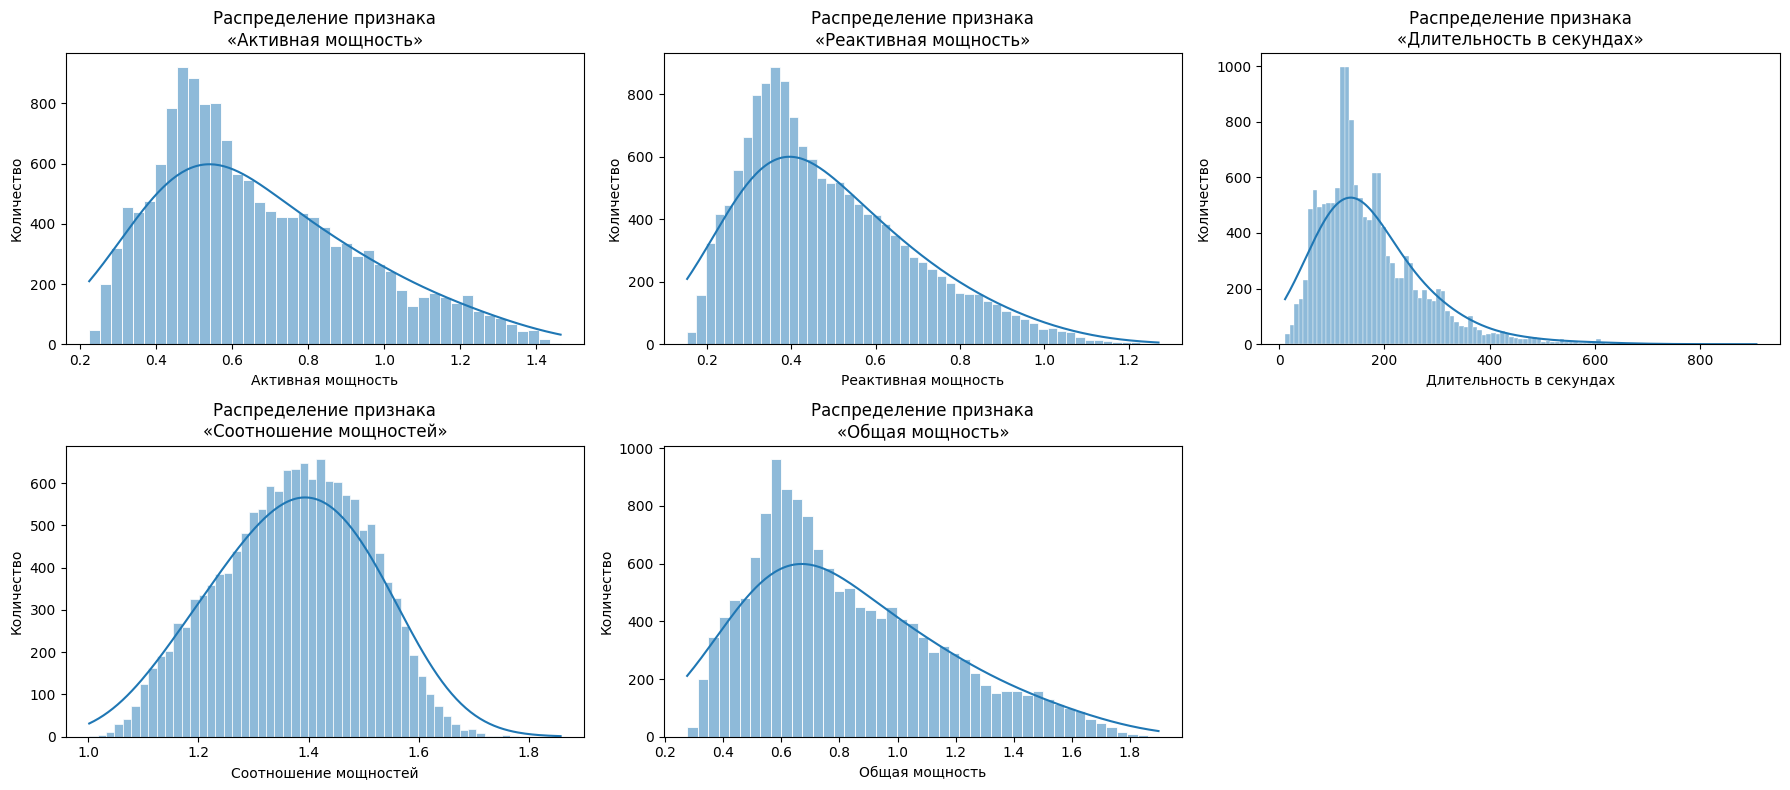

In [10]:
arc_int_cols = ['Активная мощность','Реактивная мощность','Длительность в секундах','Соотношение мощностей','Общая мощность']
data_arc.feature_display(arc_int_cols)

In [11]:
df_arc = df_arc.groupby('key').mean().reset_index()

Данные считались корректно, убрали явный выброс в данных, также было сгенерировано пара новых признаков: длительность в секундах, сооношение мощностей, общая мощность. Построили распределения признаков, все распределения имеют явную ассиметрию, кроме соотношения сторон, ее распределение близко к нормальному

In [12]:
data_bulk = EDA(bulk)
df_bulk = data_bulk.df.copy()
data_bulk.intro()

Первые пять строк и базовая инфа


,key,Bulk 1,Bulk 2,Bulk 3,Bulk 4,Bulk 5,Bulk 6,Bulk 7,Bulk 8,Bulk 9,Bulk 10,Bulk 11,Bulk 12,Bulk 13,Bulk 14,Bulk 15
0,1,NaN,NaN,NaN,43.0,None,None,None,None,None,None,None,206.0,None,150.0,154.0
1,2,NaN,NaN,NaN,73.0,None,None,None,None,None,None,None,206.0,None,149.0,154.0
2,3,NaN,NaN,NaN,34.0,None,None,None,None,None,None,None,205.0,None,152.0,153.0
3,4,NaN,NaN,NaN,81.0,None,None,None,None,None,None,None,207.0,None,153.0,154.0
4,5,NaN,NaN,NaN,78.0,None,None,None,None,None,None,None,203.0,None,151.0,152.0


,key,Bulk 1,Bulk 2,Bulk 3,Bulk 4
count,3129.000000,252.000000,22.000000,1298.000000,1014.000000
mean,1624.383509,39.242063,253.045455,113.879045,104.394477
std,933.337642,18.277654,21.180578,75.483494,48.184126
min,1.000000,10.000000,228.000000,6.000000,12.000000
25%,816.000000,27.000000,242.000000,58.000000,72.000000
50%,1622.000000,31.000000,251.500000,97.500000,102.000000
75%,2431.000000,46.000000,257.750000,152.000000,133.000000
max,3241.000000,185.000000,325.000000,454.000000,281.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   key      3129 non-null   int64  
 1   Bulk 1   252 non-null    float64
 2   Bulk 2   22 non-null     float64
 3   Bulk 3   1298 non-null   float64
 4   Bulk 4   1014 non-null   float64
 5   Bulk 5   77 non-null     object 
 6   Bulk 6   576 non-null    object 
 7   Bulk 7   25 non-null     object 
 8   Bulk 8   1 non-null      object 
 9   Bulk 9   19 non-null     object 
 10  Bulk 10  176 non-null    object 
 11  Bulk 11  177 non-null    object 
 12  Bulk 12  2450 non-null   object 
 13  Bulk 13  18 non-null     object 
 14  Bulk 14  2806 non-null   object 
 15  Bulk 15  2248 non-null   object 
dtypes: float64(4), int64(1), object(11)
memory usage: 391.3+ KB


Гистограммы непрерывных признаков


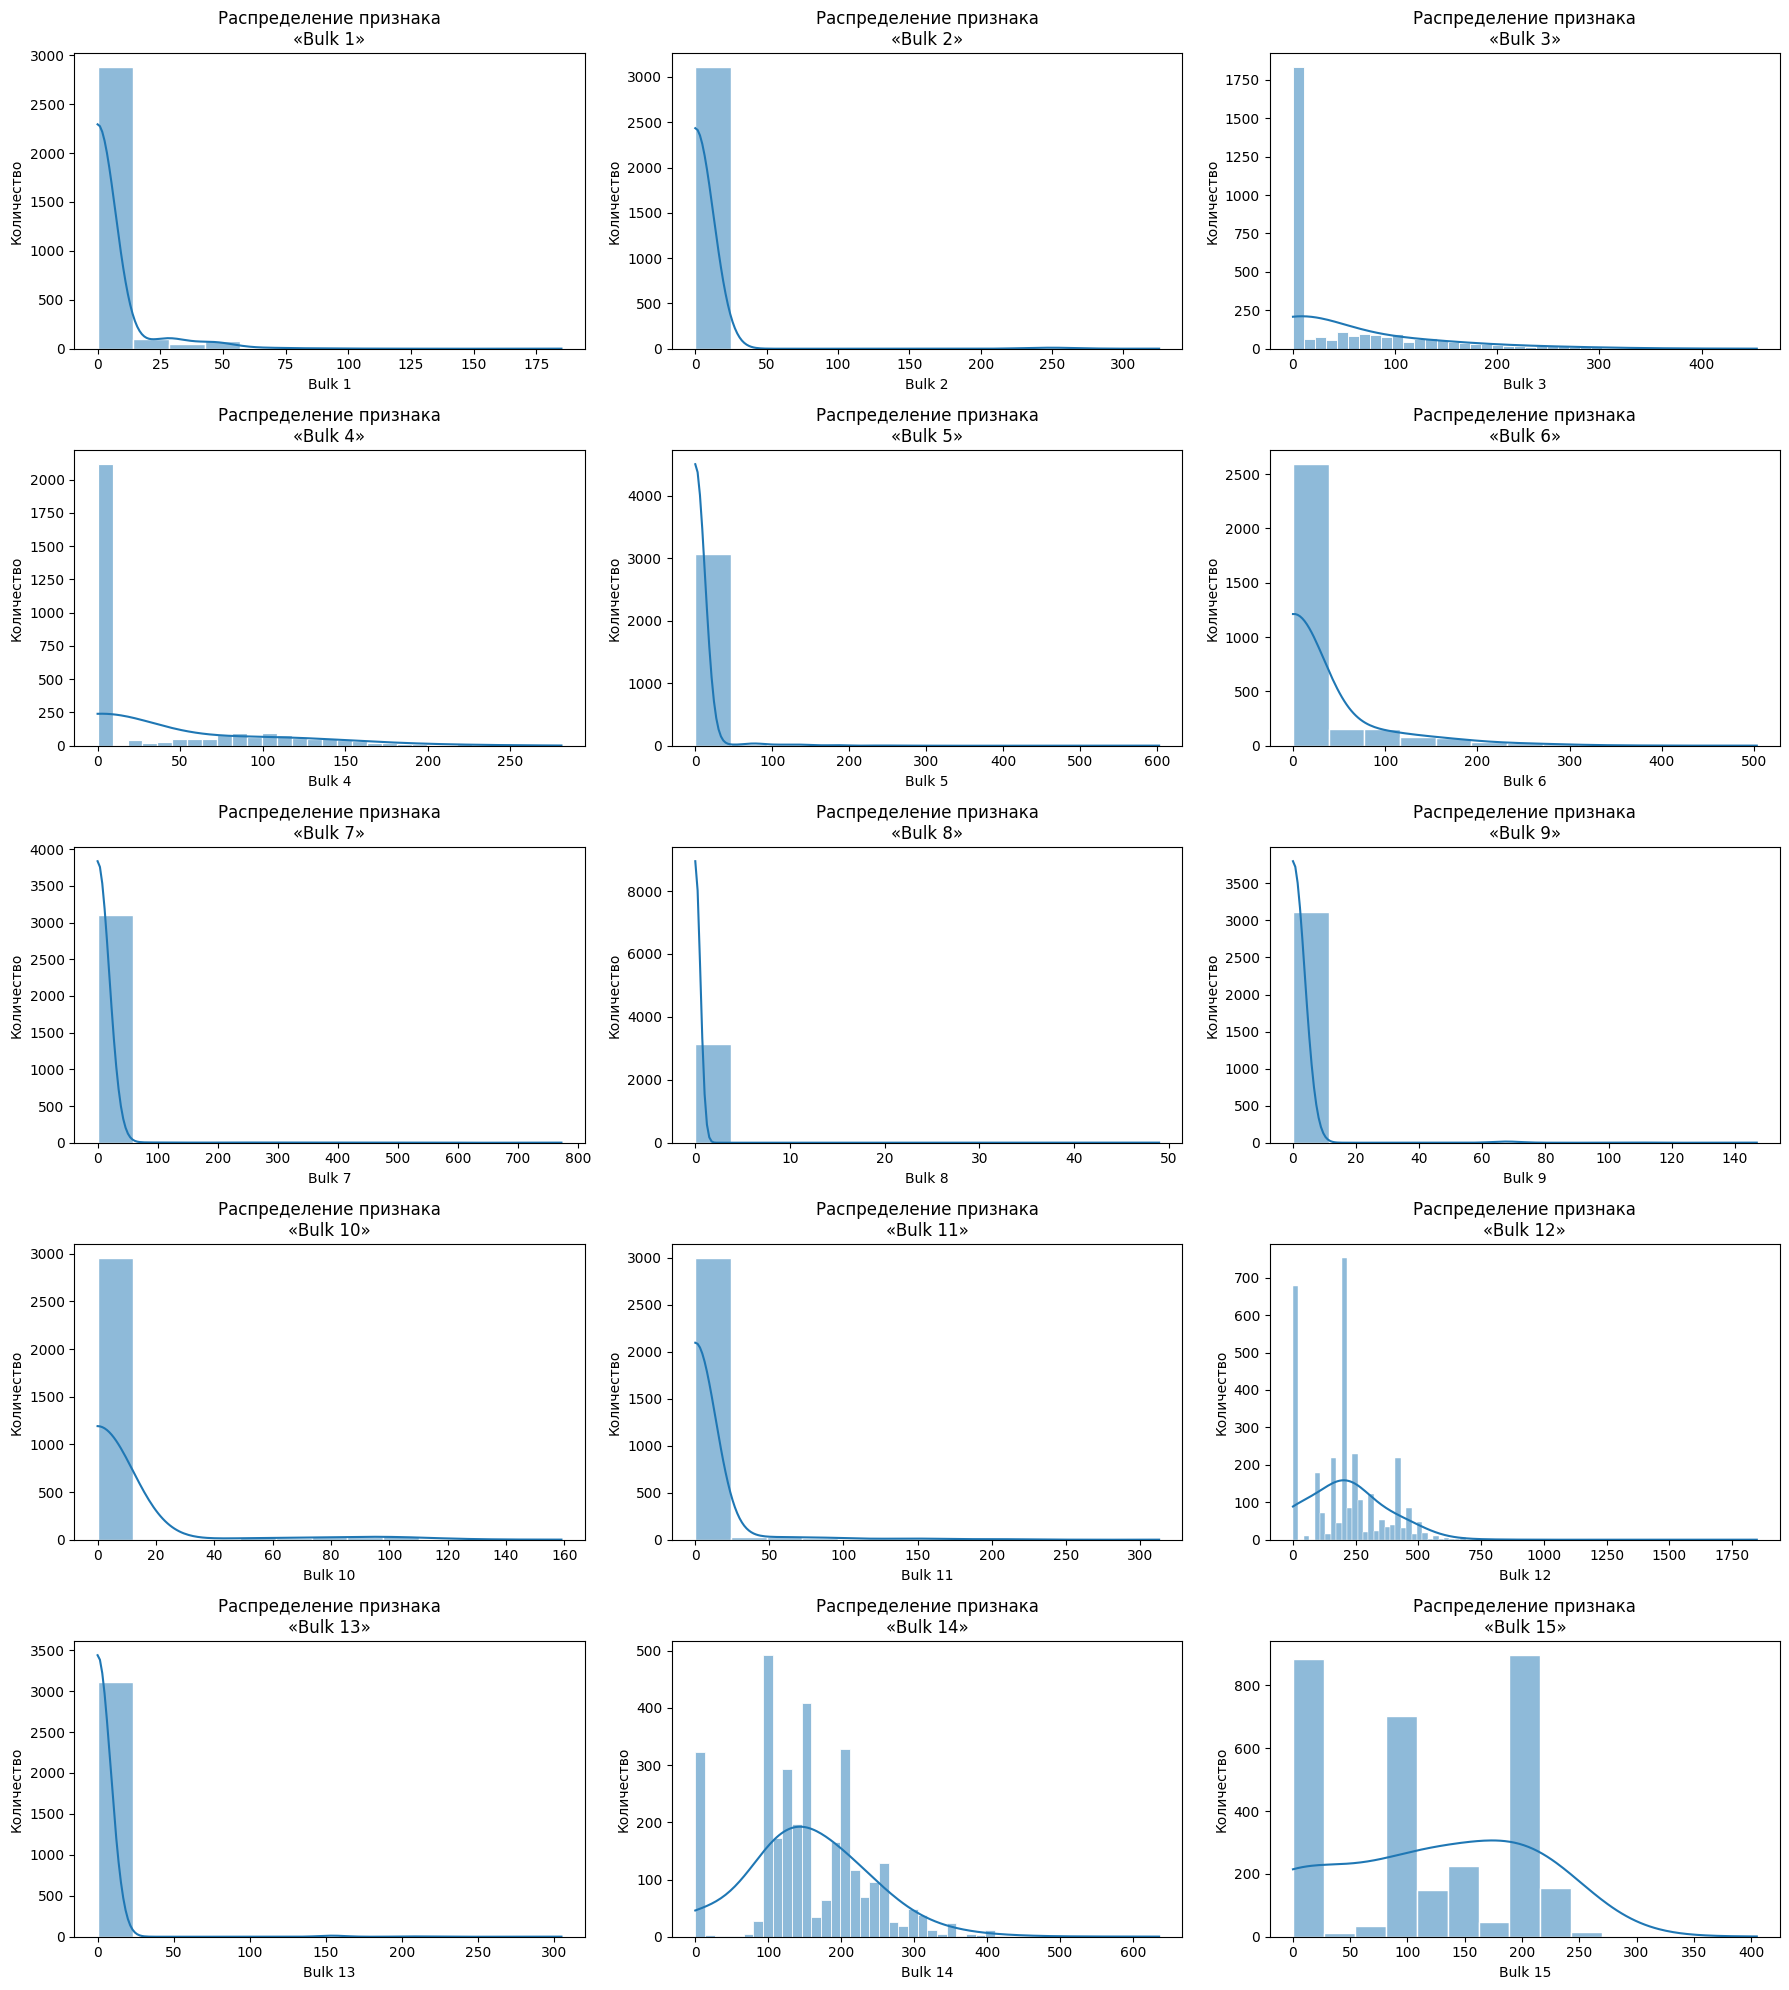

In [13]:
df_bulk = df_bulk.fillna(0)
bulk_int_cols = []
for column in df_bulk.columns:
    if column!='key':
        bulk_int_cols.append(column)
        df_bulk[column] = df_bulk[column].astype('float')

data_bulk.df = df_bulk
data_bulk.feature_display(bulk_int_cols)

Данные считались корректно, было много пропусков, но мы их заполнили нулями, так как по условию нам известно, что пропуск, это значит, что данный материал не использовался в данной партии, некоторые столбцы имели тип строки, это мы тоже поменяли. Построили распределения почти все распределения признаков с сыпучими материалами имеют явную ассиметрию и пик в 0, потому что пропусков было много, а мы их заполнили нулями в силу специфики нашей задачи, данно утверждение характерно для всех распределений, кроме материалов 12, 14 и 15, данные распределения тоже ассиметричны, и имеют частовстречающиеся значения помимо нуля, значит эти материалы часто использовались

In [14]:
df_bulk = df_bulk.groupby('key').mean().reset_index()

In [15]:
data_bulk_time = EDA(bulk_time)
df_bulk_time = data_bulk_time.df.copy()
data_bulk_time.intro()

Первые пять строк и базовая инфа


,key,Bulk 1,Bulk 2,Bulk 3,Bulk 4,Bulk 5,Bulk 6,Bulk 7,Bulk 8,Bulk 9,Bulk 10,Bulk 11,Bulk 12,Bulk 13,Bulk 14,Bulk 15
0,1,None,None,None,2019-05-03 11:28:48,None,None,None,None,None,None,None,2019-05-03 11:24:31,None,2019-05-03 11:14:50,2019-05-03 11:10:43
1,2,None,None,None,2019-05-03 11:36:50,None,None,None,None,None,None,None,2019-05-03 11:53:30,None,2019-05-03 11:48:37,2019-05-03 11:44:39
2,3,None,None,None,2019-05-03 12:32:39,None,None,None,None,None,None,None,2019-05-03 12:27:13,None,2019-05-03 12:21:01,2019-05-03 12:16:16
3,4,None,None,None,2019-05-03 12:43:22,None,None,None,None,None,None,None,2019-05-03 12:58:00,None,2019-05-03 12:51:11,2019-05-03 12:46:36
4,5,None,None,None,2019-05-03 13:30:47,None,None,None,None,None,None,None,2019-05-03 13:30:47,None,2019-05-03 13:34:12,2019-05-03 13:30:47


,key
count,3129.000000
mean,1624.383509
std,933.337642
min,1.000000
25%,816.000000
50%,1622.000000
75%,2431.000000
max,3241.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   key      3129 non-null   int64 
 1   Bulk 1   252 non-null    object
 2   Bulk 2   22 non-null     object
 3   Bulk 3   1298 non-null   object
 4   Bulk 4   1014 non-null   object
 5   Bulk 5   77 non-null     object
 6   Bulk 6   576 non-null    object
 7   Bulk 7   25 non-null     object
 8   Bulk 8   1 non-null      object
 9   Bulk 9   19 non-null     object
 10  Bulk 10  176 non-null    object
 11  Bulk 11  177 non-null    object
 12  Bulk 12  2450 non-null   object
 13  Bulk 13  18 non-null     object
 14  Bulk 14  2806 non-null   object
 15  Bulk 15  2248 non-null   object
dtypes: int64(1), object(15)
memory usage: 391.3+ KB


In [16]:
data_gas = EDA(gas)
df_gas = data_gas.df.copy()
data_gas.intro()

Первые пять строк и базовая инфа


,key,Газ 1
0,1,29.749986
1,2,12.555561
2,3,28.554793
3,4,18.841219
4,5,5.413692


,key,Газ 1
count,3239.000000,3239.000000
mean,1621.861377,11.002062
std,935.386334,6.220327
min,1.000000,0.008399
25%,812.500000,7.043089
50%,1622.000000,9.836267
75%,2431.500000,13.769915
max,3241.000000,77.995040


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3239 entries, 0 to 3238
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   key     3239 non-null   int64  
 1   Газ 1   3239 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 50.7 KB


Гистограммы непрерывных признаков


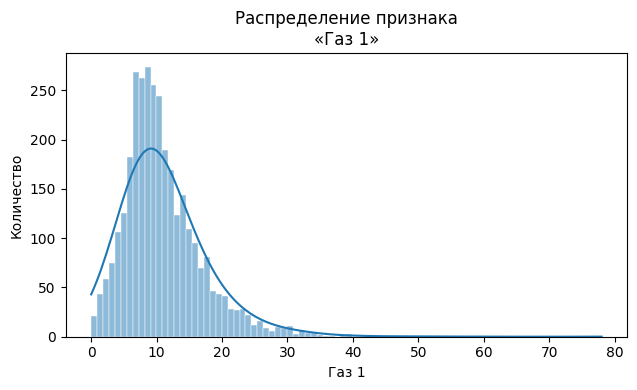

In [17]:
df_gas = df_gas[df_gas['Газ 1']<100]
gas_int_cols = ['Газ 1']
data_gas.feature_display(gas_int_cols)

Данные считались корректно, но видно, что присутствует выброс в виде выского положительного значения, его мы тоже уберем. Распределение имеет явную ассиметрию с пиком в 10

In [18]:
df_gas = df_gas.groupby('key').mean().reset_index()

In [19]:
data_temp = EDA(temp)
df_temp = data_temp.df.copy()
data_temp.intro()

Первые пять строк и базовая инфа


,key,Время замера,Температура
0,1,2019-05-03 11:02:04,1571.0
1,1,2019-05-03 11:07:18,1604.0
2,1,2019-05-03 11:11:34,1618.0
3,1,2019-05-03 11:18:04,1601.0
4,1,2019-05-03 11:25:59,1606.0


,key
count,18092.000000
mean,1616.460977
std,934.641385
min,1.000000
25%,807.750000
50%,1618.000000
75%,2429.000000
max,3241.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18092 entries, 0 to 18091
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   key           18092 non-null  int64 
 1   Время замера  18092 non-null  object
 2   Температура   14665 non-null  object
dtypes: int64(1), object(2)
memory usage: 424.2+ KB


Гистограммы непрерывных признаков


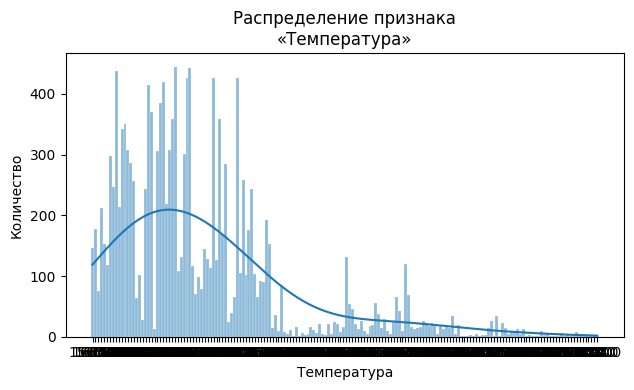

In [20]:
temp_int_cols = ['Температура']
data_temp.feature_display(temp_int_cols)

In [21]:
df_temp['Температура'] = df_temp['Температура'].astype('float')
df_temp['Температура'] = df_temp['Температура'].fillna(0)
bad_batches = []
def bad_batch(row):
    if row['Температура']<1400:
        bad_batches.append(row['key'])
df_temp.apply(bad_batch,axis=1)
df_temp = df_temp[~df_temp['key'].isin(bad_batches)]

In [22]:
df_last = df_temp.groupby('key').last().reset_index()
df_first = df_temp.groupby('key').first().reset_index()

Данные считались корректно, надо было поменять тип на float, был сделан новый признак, начальная температура для партии. Распределение имеет ассиметрию, не имеет явного пика, но по гистограмме видно, что в целом низкие значения превалируют над высокими

In [23]:
data_wire = EDA(wire)
df_wire = data_wire.df.copy()
data_wire.intro()

Первые пять строк и базовая инфа


,key,Wire 1,Wire 2,Wire 3,Wire 4,Wire 5,Wire 6,Wire 7,Wire 8,Wire 9
0,1,60.059998,None,None,None,None,None,None,None,None
1,2,96.052315,None,None,None,None,None,None,None,None
2,3,91.160157,None,None,None,None,None,None,None,None
3,4,89.063515,None,None,None,None,None,None,None,None
4,5,89.238236,9.11456,None,None,None,None,None,None,None


,key,Wire 1
count,3081.000000,3055.000000
mean,1623.426485,100.895853
std,932.996726,42.012518
min,1.000000,1.918800
25%,823.000000,72.115684
50%,1619.000000,100.158234
75%,2434.000000,126.060483
max,3241.000000,330.314424


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   key     3081 non-null   int64  
 1   Wire 1  3055 non-null   float64
 2   Wire 2  1079 non-null   object 
 3   Wire 3  63 non-null     object 
 4   Wire 4  14 non-null     object 
 5   Wire 5  1 non-null      object 
 6   Wire 6  73 non-null     object 
 7   Wire 7  11 non-null     object 
 8   Wire 8  19 non-null     object 
 9   Wire 9  29 non-null     object 
dtypes: float64(1), int64(1), object(8)
memory usage: 240.8+ KB


Гистограммы непрерывных признаков


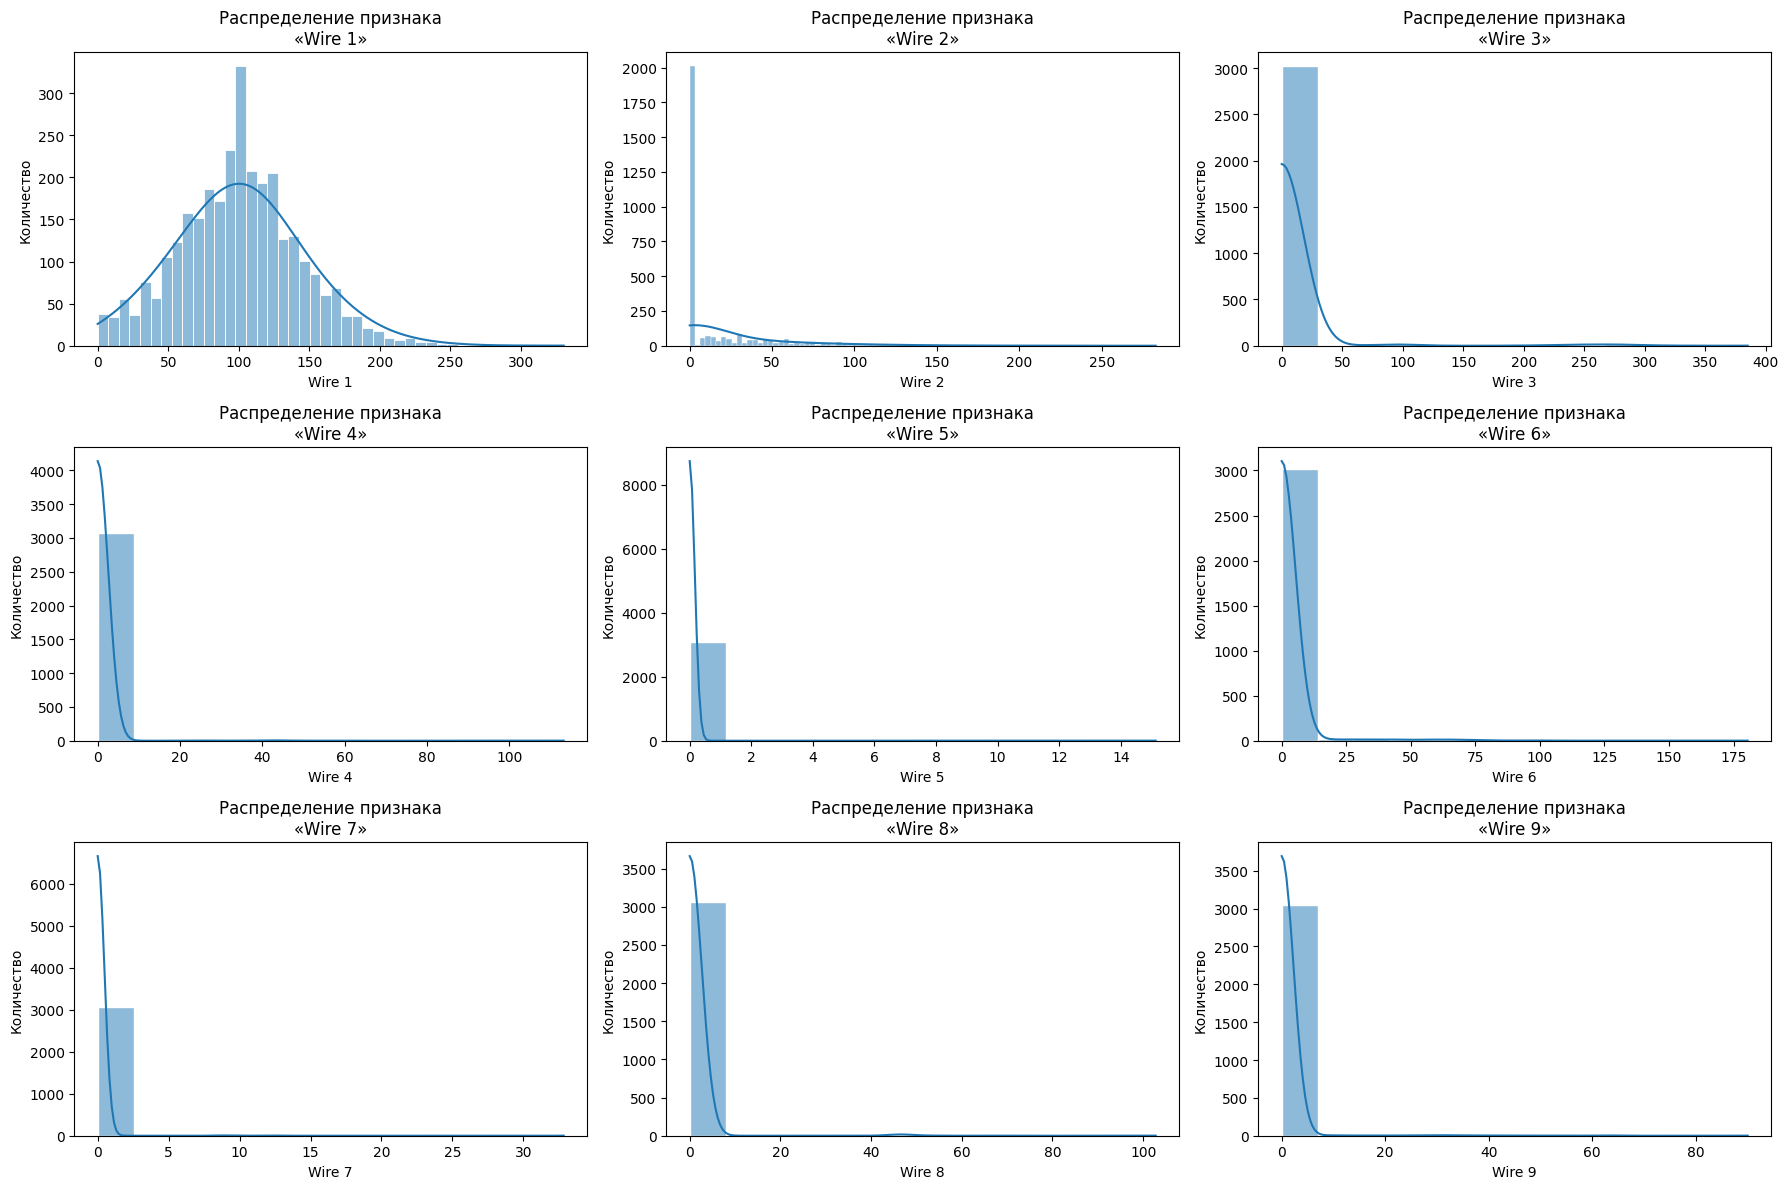

In [24]:
df_wire = df_wire.fillna(0)
wire_int_cols = []
for column in df_wire.columns:
    if column!='key':
        wire_int_cols.append(column)
        df_wire[column] = df_wire[column].astype('float')

data_wire.df = df_wire
data_wire.feature_display(wire_int_cols)

Идентичная ситуация, что и в таблице с сыпучими материалами - заполнили пропуски нулями, по тем же причинам, поменяли типы у столбцов на нужные, все распределения из за проделанных операций имеют явную ассиметрию, кроме 1 проволочного материала, он особенный, он имеет нормальное распределение

In [25]:
data_wire_time = EDA(wire_time)
df_wire_time = data_wire_time.df.copy()
data_wire_time.intro()

Первые пять строк и базовая инфа


,key,Wire 1,Wire 2,Wire 3,Wire 4,Wire 5,Wire 6,Wire 7,Wire 8,Wire 9
0,1,2019-05-03 11:06:19,None,None,None,None,None,None,None,None
1,2,2019-05-03 11:36:50,None,None,None,None,None,None,None,None
2,3,2019-05-03 12:11:46,None,None,None,None,None,None,None,None
3,4,2019-05-03 12:43:22,None,None,None,None,None,None,None,None
4,5,2019-05-03 13:20:44,2019-05-03 13:15:34,None,None,None,None,None,None,None


,key
count,3081.000000
mean,1623.426485
std,932.996726
min,1.000000
25%,823.000000
50%,1619.000000
75%,2434.000000
max,3241.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   key     3081 non-null   int64 
 1   Wire 1  3055 non-null   object
 2   Wire 2  1079 non-null   object
 3   Wire 3  63 non-null     object
 4   Wire 4  14 non-null     object
 5   Wire 5  1 non-null      object
 6   Wire 6  73 non-null     object
 7   Wire 7  11 non-null     object
 8   Wire 8  19 non-null     object
 9   Wire 9  29 non-null     object
dtypes: int64(1), object(9)
memory usage: 240.8+ KB


По итогу исследовательского анализа данных можно сказать, что пропусков нет, все данные мы подправили и создали новые признаки. По поводу рапсределений, для таблицы об электродах все распределения кроме соотношения мощностей имеют явную ассиметрию, рапределениие соотношения мощностей является близким к нормальному. Для таблицы с объемом сыпучих материалов, почти все материалы имеют яркую ассиметрию с огромным пиком в нуле, это относится ко всем столбцам кроме материалов 12, 14 и 15 - их распределения нельзя отнести к конкретному типу. Таблица про газы имеет асимметричное распределение с пиком в 10. Таблица с таргетом тоже имеет асимметрию, но там четкого пика нет, самая большая частота находится на низких значениях температуры. С проволчными материалами та же ситуация, что и с сыпучими везде ассиметрия с пиком в нуле, кроме 1 материала оно имеет нормальное распредление с пиком в 100

In [26]:
df_main = df_arc.merge(df_bulk, on='key', how='inner').merge(df_gas, on='key', how='inner').merge(df_first, on='key', how='inner').merge(df_last, on='key', how='inner').merge(df_wire, on='key', how='inner')

In [27]:
display(df_main.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2324 entries, 0 to 2323
Data columns (total 37 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   key                      2324 non-null   int64         
 1   Начало нагрева дугой     2324 non-null   datetime64[ns]
 2   Конец нагрева дугой      2324 non-null   datetime64[ns]
 3   Активная мощность        2324 non-null   float64       
 4   Реактивная мощность      2324 non-null   float64       
 5   Длительность в секундах  2324 non-null   float64       
 6   Соотношение мощностей    2324 non-null   float64       
 7   Общая мощность           2324 non-null   float64       
 8   Bulk 1                   2324 non-null   float64       
 9   Bulk 2                   2324 non-null   float64       
 10  Bulk 3                   2324 non-null   float64       
 11  Bulk 4                   2324 non-null   float64       
 12  Bulk 5                   2324 non-

None

In [28]:
int_cols = []
df_main = df_main.rename(columns={'Температура_x': 'Начальная температура','Температура_y': 'target'})
for column in df_main.columns:
    if column not in ['key','Начало нагрева дугой','Конец нагрева дугой','Время замера_x','Время замера_y']:
        int_cols.append(column)
data_main = EDA(df_main)
data_main.intro()

Первые пять строк и базовая инфа


,key,Начало нагрева дугой,Конец нагрева дугой,Активная мощность,Реактивная мощность,Длительность в секундах,Соотношение мощностей,Общая мощность,Bulk 1,Bulk 2,...,target,Wire 1,Wire 2,Wire 3,Wire 4,Wire 5,Wire 6,Wire 7,Wire 8,Wire 9
0,1,2019-05-03 11:13:09.800000000,2019-05-03 11:16:49.400000000,0.607346,0.428564,219.60,1.421570,0.743747,0.0,0.0,...,1613.0,60.059998,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,2019-05-03 11:42:17.750000128,2019-05-03 11:45:40.500000000,0.534852,0.363339,202.75,1.479201,0.647087,0.0,0.0,...,1602.0,96.052315,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3,2019-05-03 12:19:19.800000000,2019-05-03 12:21:30.800000000,0.812728,0.587491,131.00,1.396069,1.003845,0.0,0.0,...,1599.0,91.160157,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,2019-05-03 12:46:27.500000000,2019-05-03 12:49:32.750000128,0.676622,0.514248,185.25,1.307446,0.850010,0.0,0.0,...,1625.0,89.063515,0.00000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5,2019-05-03 13:21:27.500000000,2019-05-03 13:25:04.750000128,0.563238,0.421998,217.25,1.328894,0.704245,0.0,0.0,...,1602.0,89.238236,9.11456,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,key,Начало нагрева дугой,Конец нагрева дугой,Активная мощность,Реактивная мощность,Длительность в секундах,Соотношение мощностей,Общая мощность,Bulk 1,Bulk 2,...,target,Wire 1,Wire 2,Wire 3,Wire 4,Wire 5,Wire 6,Wire 7,Wire 8,Wire 9
count,2324.000000,2324,2324,2324.000000,2324.000000,2324.000000,2324.000000,2324.000000,2324.000000,2324.000000,...,2324.000000,2324.000000,2324.000000,2324.000000,2324.000000,2324.0,2324.000000,2324.000000,2324.000000,2324.000000
mean,1251.140275,2019-06-21 00:20:15.598972160,2019-06-21 00:23:07.717095936,0.664209,0.488921,172.118124,1.371584,0.825641,3.435026,1.425559,...,1593.372633,102.423900,17.613213,3.241876,0.307209,0.0,0.980926,0.006374,0.311981,0.317795
min,1.000000,2019-05-03 11:13:09.800000,2019-05-03 11:16:49.400000,0.267676,0.196228,57.000000,1.099589,0.331897,0.000000,0.000000,...,1541.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
25%,628.750000,2019-05-27 08:37:34.187500032,2019-05-27 08:40:43.375000064,0.576159,0.420039,141.000000,1.329268,0.714277,0.000000,0.000000,...,1587.000000,73.204559,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
50%,1254.500000,2019-06-19 21:28:31.400000,2019-06-19 21:31:28.500000,0.655834,0.484669,169.500000,1.372134,0.818302,0.000000,0.000000,...,1593.000000,101.103600,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
75%,1867.250000,2019-07-11 17:38:08.937499904,2019-07-11 17:42:44.437499904,0.741883,0.546693,198.750000,1.414823,0.921313,0.000000,0.000000,...,1598.000000,128.075222,23.102560,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
max,2499.000000,2019-08-10 13:44:14.750000128,2019-08-10 13:47:55.500000,1.243889,0.960763,378.000000,1.663366,1.572238,185.000000,325.000000,...,1653.000000,330.314424,282.780152,385.008668,113.231044,0.0,180.454575,8.490040,102.762401,62.025600
std,715.027927,NaN,NaN,0.128419,0.098024,43.740469,0.065984,0.160411,12.424463,19.102530,...,11.207457,43.540975,33.648176,27.972523,4.762842,0.0,8.702531,0.205926,4.407419,3.460248


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2324 entries, 0 to 2323
Data columns (total 37 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   key                      2324 non-null   int64         
 1   Начало нагрева дугой     2324 non-null   datetime64[ns]
 2   Конец нагрева дугой      2324 non-null   datetime64[ns]
 3   Активная мощность        2324 non-null   float64       
 4   Реактивная мощность      2324 non-null   float64       
 5   Длительность в секундах  2324 non-null   float64       
 6   Соотношение мощностей    2324 non-null   float64       
 7   Общая мощность           2324 non-null   float64       
 8   Bulk 1                   2324 non-null   float64       
 9   Bulk 2                   2324 non-null   float64       
 10  Bulk 3                   2324 non-null   float64       
 11  Bulk 4                   2324 non-null   float64       
 12  Bulk 5                   2324 non-

Гистограммы непрерывных признаков


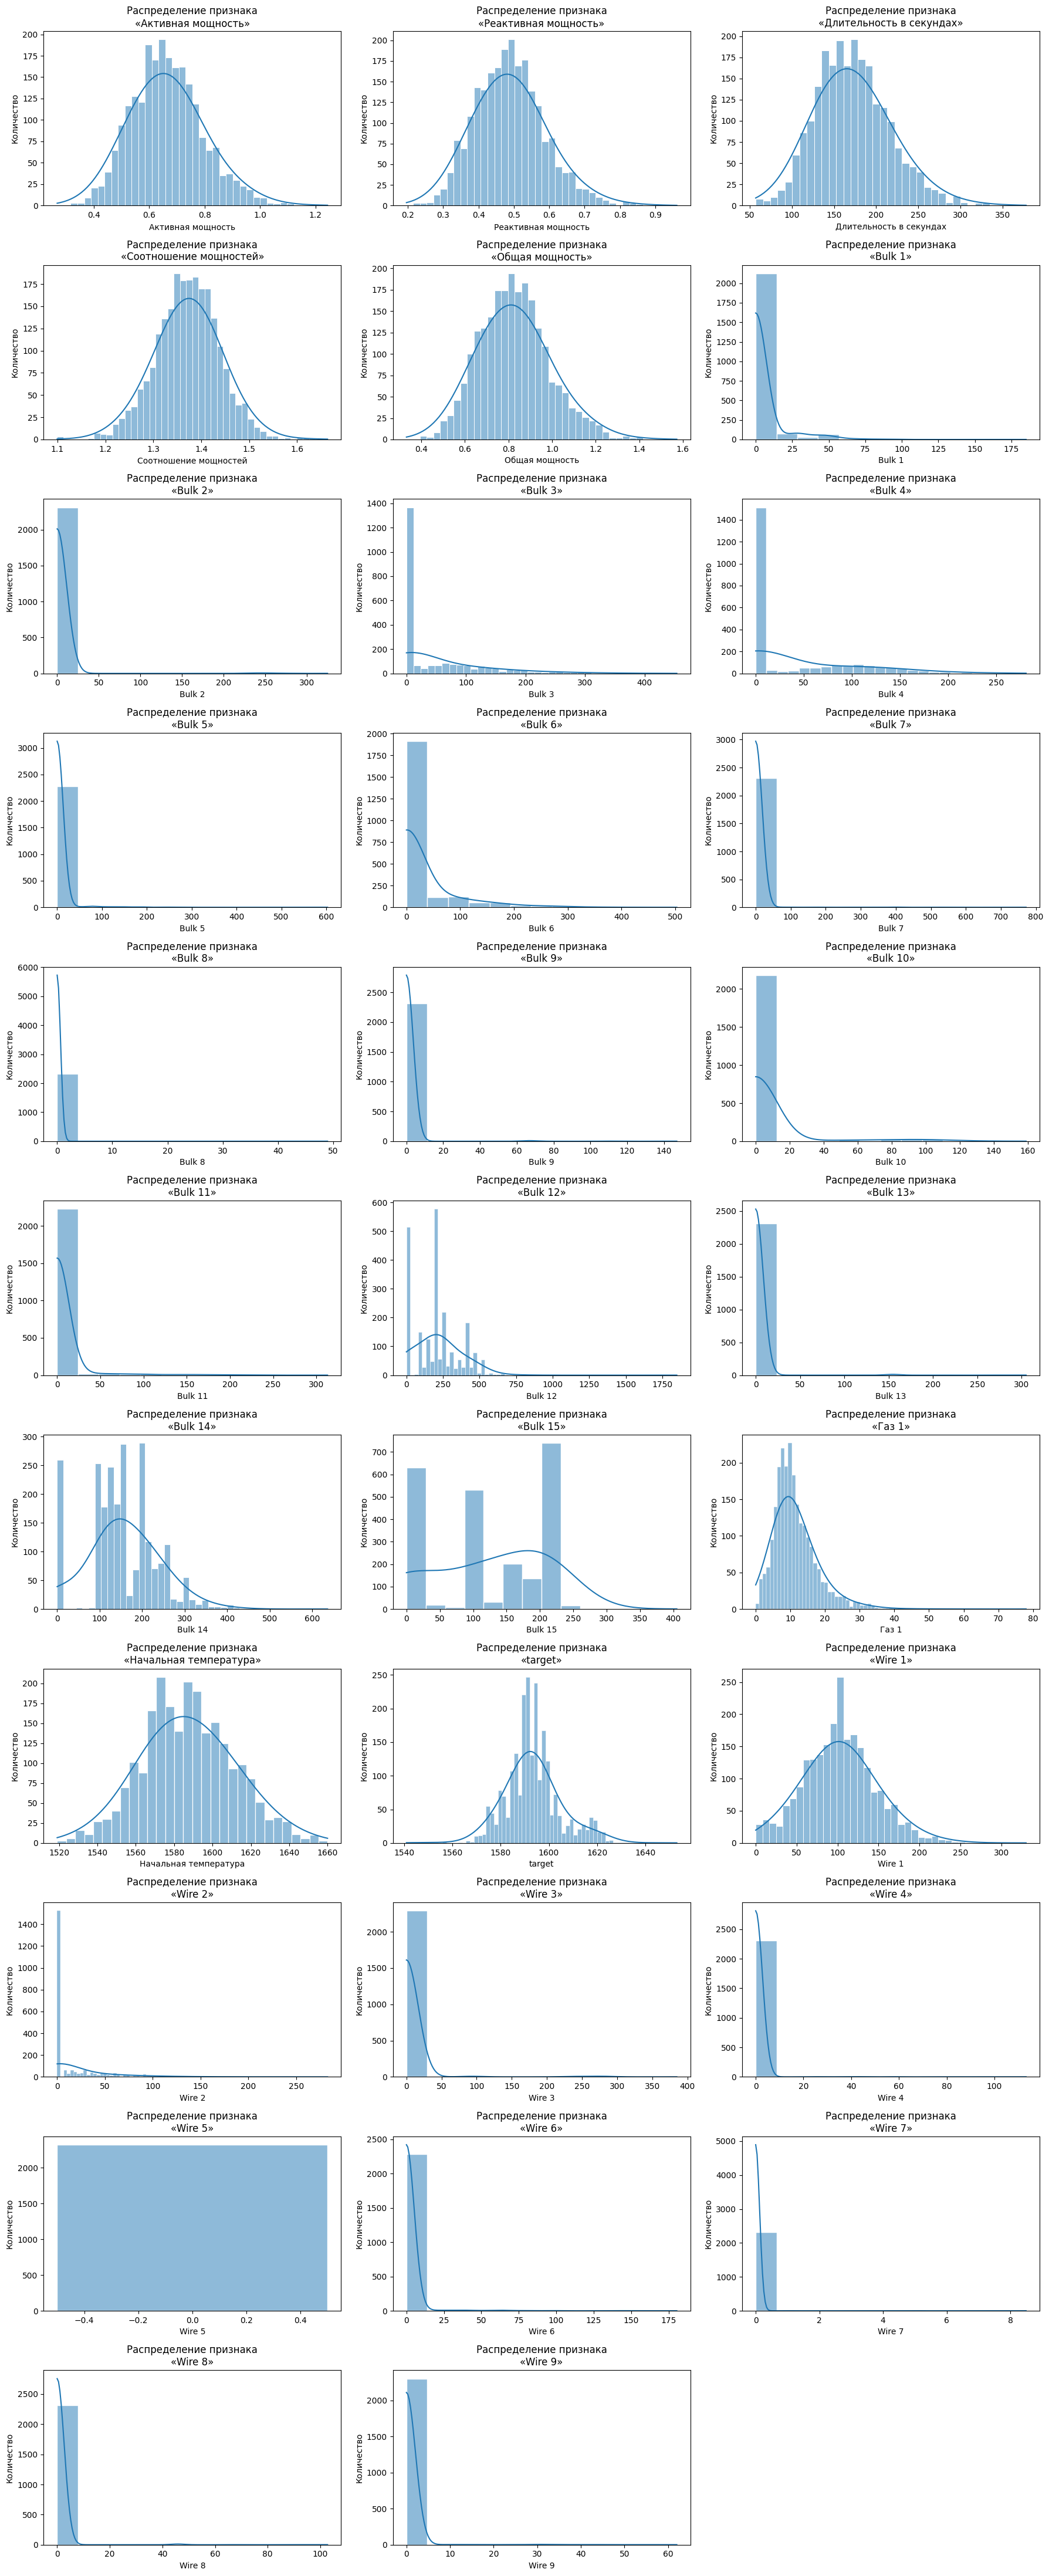

In [29]:
data_main.feature_display(int_cols)

Все распределения из таблицы про электроды нормальные. Что касается сыпучих материалов, то там везде асимметрия с пиком в 0, кроме материалов 12, 14 и 15, которые часто встречаются и имеют пики в других значениях. Подача газа имеет ассиматрию с пиком в 10. Начальная и конечная температура имеют нормальные распределения, за исключением того, что начальная имеет больший разлет в значениях, а конечная более узенькая. Теперь по поводу проволочных, почти все имеют явную ассиметрию с пиком в нуле, кроме двух материалов, первый имеет как и раньше нормальное распределение, а с пятым материалом произошло страшное, из за того, что мы поудаляли неправильные ковши он стал константой ноль, ну тогда мы его в дальнейших этапах откинем, он не нужен

In [30]:
df_main = df_main.drop(['key','Начало нагрева дугой','Конец нагрева дугой','Время замера_x','Время замера_y','Wire 5'],axis=1)
data_main.df = df_main

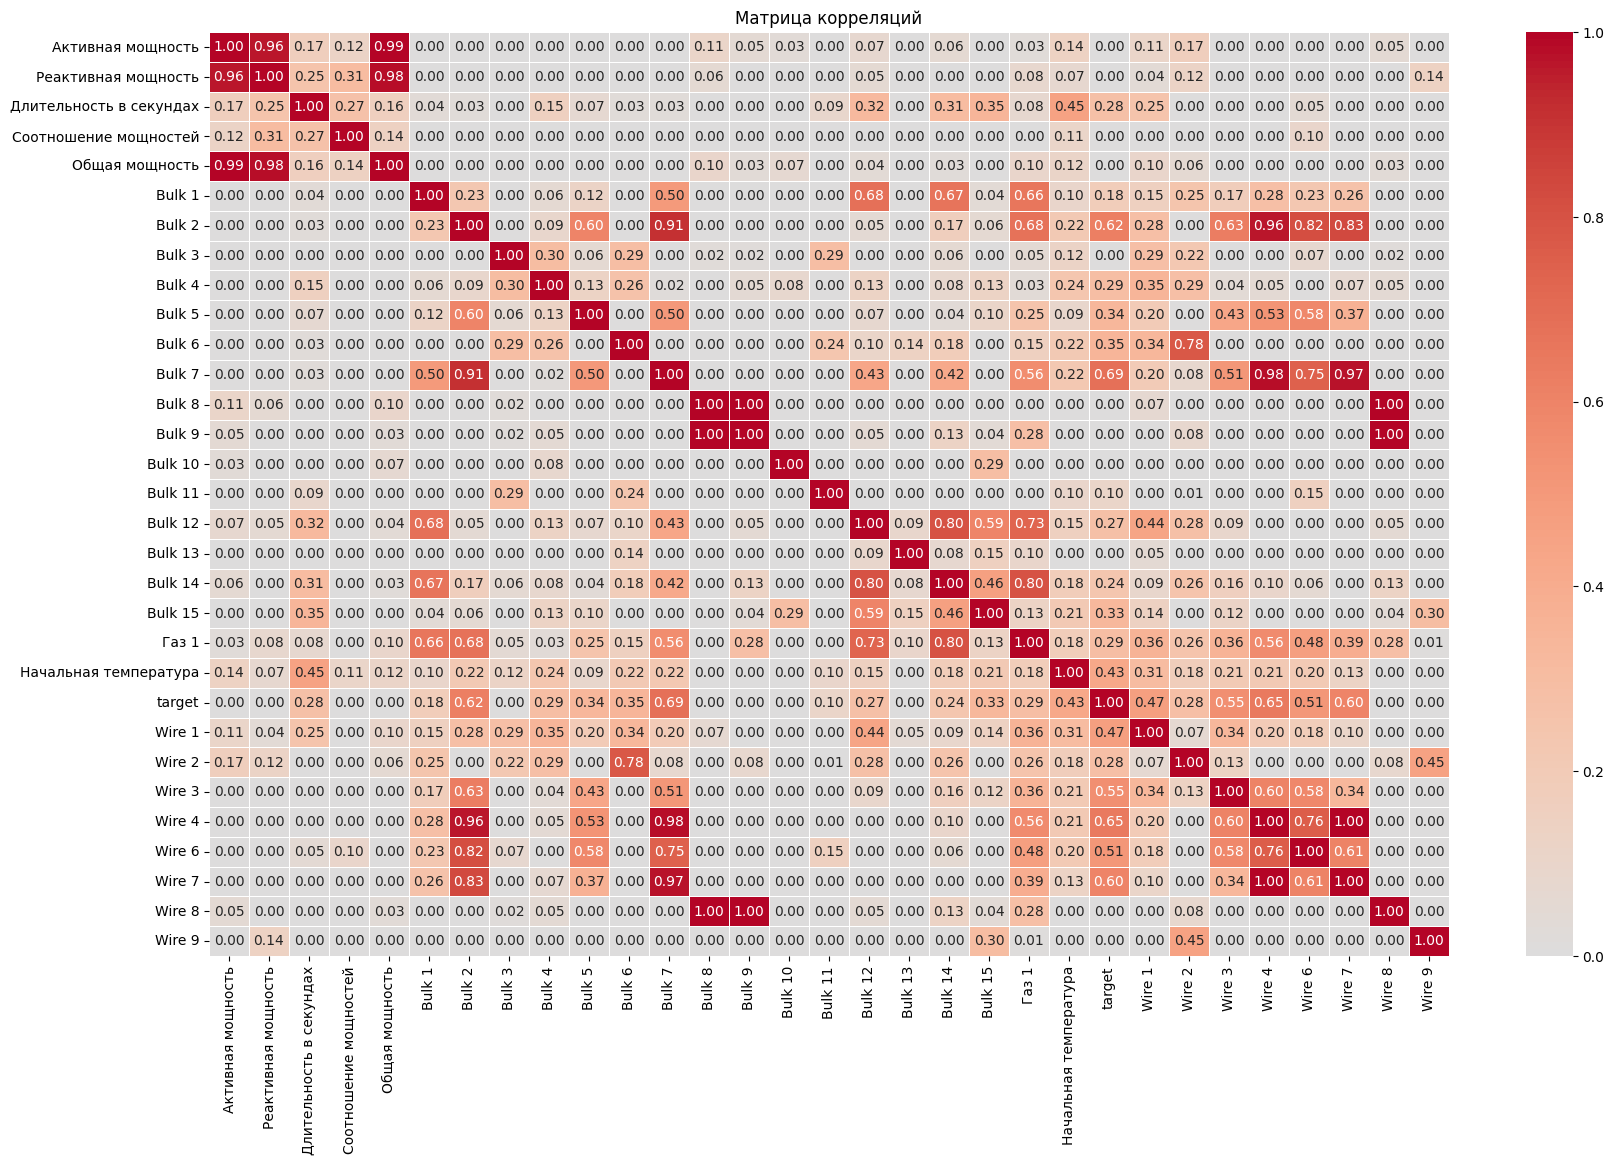

In [31]:
data_main.phik_matrix(int_cols)

Посмотря на матрицу корреляций, можно сказать, что утечек целевого признака нет, но есть мультиколлинеарности, в частности проблемными оказались признаки с активной и общей мощностью, седьмой и восьмой сыпучий материал, восьмой и четвертый проволочный

In [32]:
df_main = df_main.drop(['Активная мощность','Общая мощность','Bulk 7','Bulk 8','Wire 4','Wire 8'],axis=1)
data_main.df = df_main

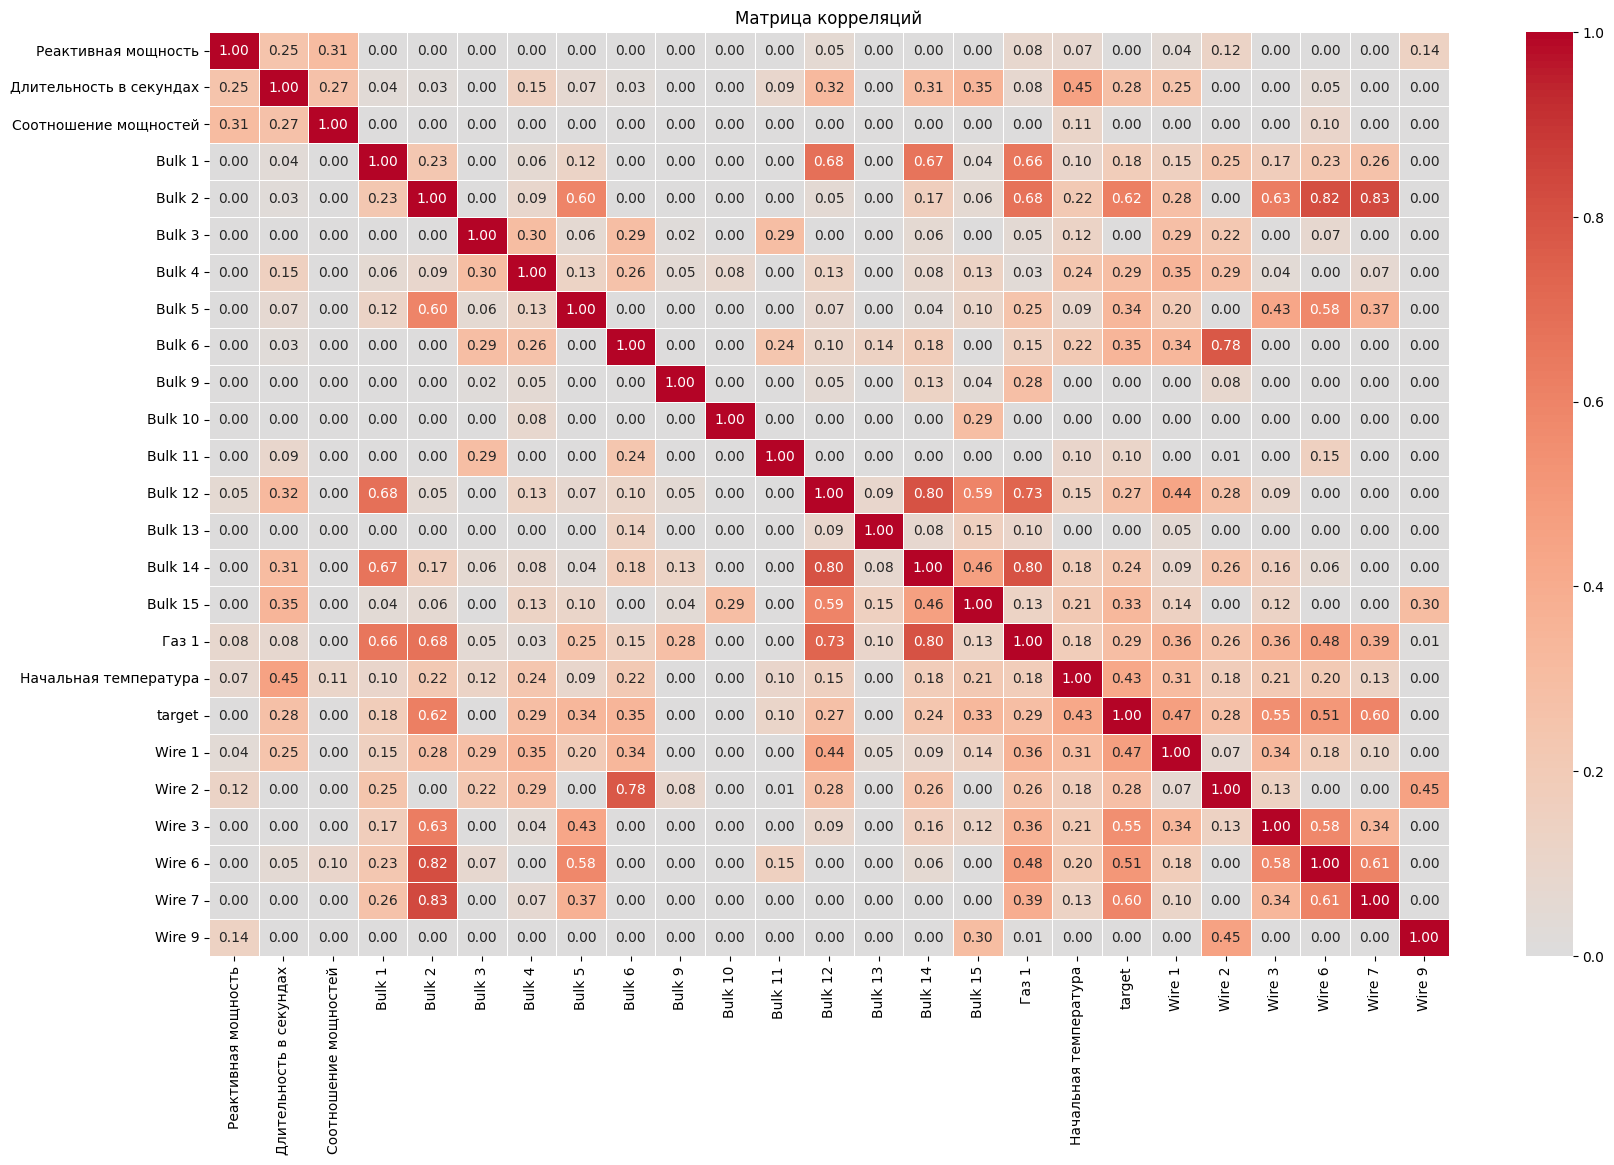

In [33]:
data_main.phik_matrix(int_cols)

Теперь красиво

In [34]:
X = df_main.drop('target',axis=1)
y = df_main['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=13052026,test_size=0.25)

In [35]:
int_cols = X_test.columns
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Обучим мы три модели: нейронную полносвязную сеть, катбуст и решающее дерево, метрику будем использовать МАЕ, будем обучать модели через подбор гиперпараметров

In [36]:
class Net(nn.Module):
    def __init__(self, n_in_neurons, n_hidden_neurons_1, n_hidden_neurons_2, n_hidden_neurons_3, n_out_neurons):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(n_in_neurons, n_hidden_neurons_1)
        self.bn1 = nn.BatchNorm1d(n_hidden_neurons_1)
        self.fc2 = nn.Linear(n_hidden_neurons_1, n_hidden_neurons_2)
        self.bn2 = nn.BatchNorm1d(n_hidden_neurons_2)
        self.fc3 = nn.Linear(n_hidden_neurons_2, n_hidden_neurons_3)
        self.bn3 = nn.BatchNorm1d(n_hidden_neurons_3)
        self.fc4 = nn.Linear(n_hidden_neurons_3, n_out_neurons)

    def forward(self, x):
        x = self.fc1(x)
        x = self.bn1(x)
        x = torch.relu(x)
        x = self.fc2(x)
        x = self.bn2(x)
        x = torch.relu(x)
        x = self.fc3(x)
        x = self.bn3(x)
        x = torch.relu(x)
        x = self.fc4(x)
        return x

In [37]:
model = NeuralNetRegressor(
    Net,
    max_epochs=30,
    optimizer=torch.optim.Adam,
    criterion=nn.MSELoss,
    verbose=0,
    device='cuda'
)

In [38]:
pipe_final = Pipeline([
    ('models', DecisionTreeRegressor(random_state=13052026))
])


param_tree = [
    {
        'models': [DecisionTreeRegressor(random_state=13052026)],
        'models__max_depth': range(2,5),
        'models__max_features': range(2,5), 
    }]

param_catboost = [
    {
        'models': [CatBoostRegressor(random_state=13052026,early_stopping_rounds=50,logging_level='Silent')],
        'models__iterations': [100, 500],
        'models__learning_rate': [0.01, 0.05, 0.1], 
        'models__depth': [4, 6, 8],  
    }
]

param_neuro = {
    'module__n_in_neurons':      [X_train.shape[1]], 
    'module__n_hidden_neurons_1': [256],
    'module__n_hidden_neurons_2': [128],
    'module__n_hidden_neurons_3': [64],
    'module__n_out_neurons':     [1],              
    'lr':                        [1e-3, 1e-4],
    'max_epochs':                [20, 3000],
}

In [39]:
tree_search = GridSearchCV(
    pipe_final, 
    param_tree, 
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

catboost_search = GridSearchCV(
    pipe_final, 
    param_catboost, 
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

neuro_search = GridSearchCV(
    model,
    param_neuro,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=0
)

neuro_search.fit(X_train.astype('float32'),y_train.values.reshape(-1, 1).astype('float32'))
tree_search.fit(X_train, y_train)
catboost_search.fit(X_train, y_train)
print('Лучшая метрика решающего дерева', tree_search.best_score_)
print()
print('Лучшая метрика катбуста', catboost_search.best_score_)
print()
print ('Лучшая метрика нейронной сети', neuro_search.best_score_)

/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Лучшая метрика решающего дерева -7.760584270769874

Лучшая метрика катбуста -6.675871016706891

Лучшая метрика нейронной сети -20.677703857421875


In [40]:
results = [
    ['Дерево решений',tree_search.best_score_,tree_search.best_params_],
    ['Катбуст',catboost_search.best_score_,catboost_search.best_params_],
    ['Нейронная сеть',neuro_search.best_score_,neuro_search.best_params_]
]
result_df = pd.DataFrame(results,columns=['модель','метрика','гиперапараметры'])
display(result_df)

,модель,метрика,гиперапараметры
0,Дерево решений,-7.760584,{'models': DecisionTreeRegressor(random_state=...
1,Катбуст,-6.675871,{'models': CatBoostRegressor(early_stopping_ro...
2,Нейронная сеть,-20.677704,"{'lr': 0.001, 'max_epochs': 3000, 'module__n_h..."


In [41]:
preds = catboost_search.predict(X_test)

In [42]:
print(mean_absolute_error(y_test,preds))

6.738331118003293


In [43]:
best_pipeline = catboost_search.best_estimator_

catboost_model = best_pipeline.named_steps['models']

In [44]:
explainer = shap.TreeExplainer(catboost_model, data=X_train)

shap_values = explainer.shap_values(X_test)

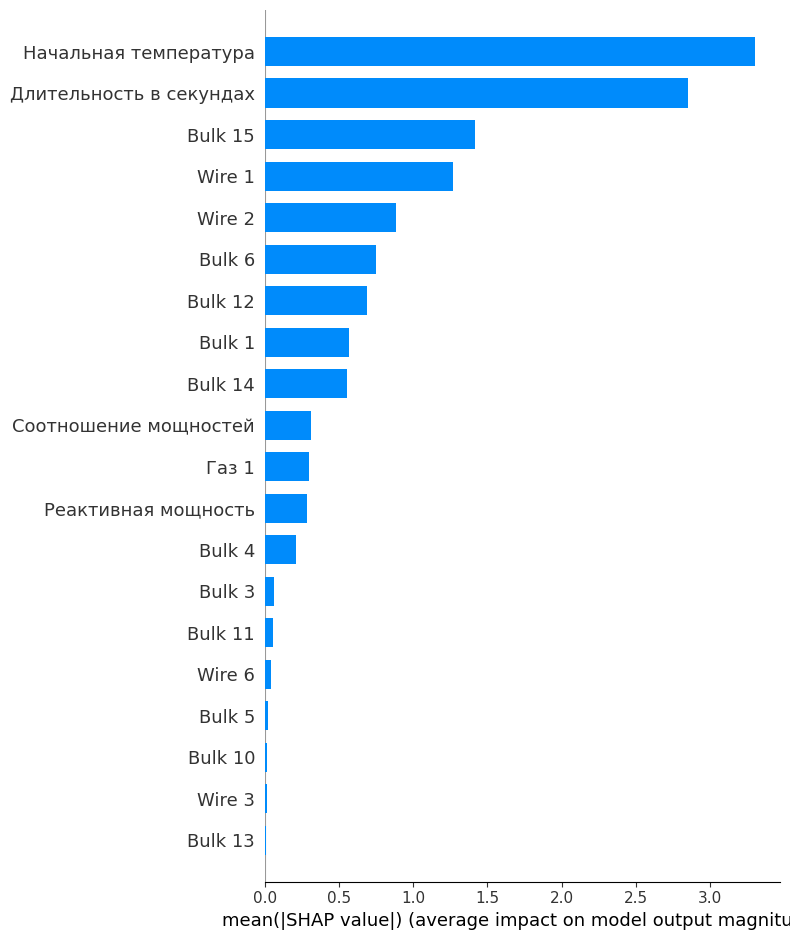

In [45]:
shap.summary_plot(shap_values, X_test, plot_type="bar", feature_names=int_cols)

Самым важным признаком оказалась начальная температура

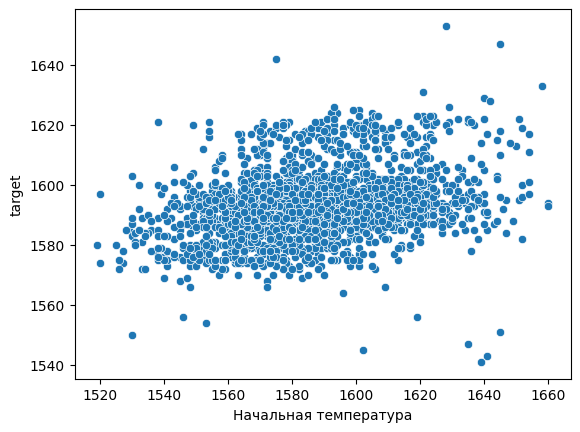

In [46]:
sns.scatterplot(data=df_main, x='Начальная температура', y='target')
plt.show()

Начальная температура прямопропорциональна таргету, немного, но заметен наклон графика и что чем больше начальная температура, тем больше и таргет

По итогу выполнения проекта можно сказать, что данные были загружены и корректно считаны, пропуски были заполнены, либо опущены, проведен исследовательский анализ данных, подготовлены данные к обучению и обучены три модели, из которых лучше всего себя показал катбуст. Самым важным признаком оказалась начальная температура. По поводу рекомендаций к улучшению модели, можно выделить больше времени и погонять гиперпаарметры для лучшей метрики